In [1]:

import torch
import numpy as np 

import matplotlib.pyplot as plt


device = 'cuda'
rnd_state = np.random.RandomState(1231415)

In [3]:
import torch
import time

# Set matrix size
N, M = 1000, 1000

# Move to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Warm-up CUDA (first call is usually slower due to initialization)
if torch.cuda.is_available():
    _ = torch.randn((N, M), device=device)

# Measure execution time
torch.cuda.synchronize() if torch.cuda.is_available() else None
start_time = time.time()
_ = torch.randn((N, M), device=device)
torch.cuda.synchronize() if torch.cuda.is_available() else None
elapsed_time = time.time() - start_time

# Estimate FLOPs (assuming 5-12 FLOPs per sample)
min_flops = 5 * N * M
max_flops = 12 * N * M
flops_per_sec = (min_flops / elapsed_time, max_flops / elapsed_time)

# Print results
print(f"Elapsed Time: {elapsed_time:.6f} sec")
print(f"Estimated FLOPs per second: {flops_per_sec[0]:.2e} to {flops_per_sec[1]:.2e} FLOP/s")


Elapsed Time: 0.002243 sec
Estimated FLOPs per second: 2.23e+09 to 5.35e+09 FLOP/s


In [3]:
d = 50

A = rnd_state.randn(d, d)

A = A.T @ A

#v = (5100 - 1000) * rnd_state.randn(d) + 1000
#indices = rnd_state.choice(d, d - 2, replace=False)
#v[indices] = 0.0

#A = np.diag(v)


In [33]:


def target(x):
    return 0.5 * np.square(np.linalg.norm(A.dot(x))) + (2 *0.0001 * rnd_state.rand(1) - 0.0001)#x.T.dot(A.dot(x))
    
def grad(x):
    return A.T @ (A.dot(x))
 
def compute_g(f, x, h, P, dir_type=0):
    g = np.zeros_like(x)
#    fx = f(x)
    for i in range(P.shape[1]):
        g+= ((f(x + h * P[:, i]) - f(x) )/h) * P[:, i]
    if dir_type == 0:
        g *= P.shape[0] / P.shape[1]
    else:
        g *= 1 / P.shape[1]
    return g


def compute_og(f, x, h, P, dir_type=0):
    alpha = np.zeros((P.shape[1], ))
#    fx = f(x)
    for i in range(P.shape[1]):
        alpha[i]=(f(x + h * P[:, i]) - f(x) )/h
        
    nrm_const = (P.shape[1] / P.shape[0]) if dir_type == 0 else P.shape[1] 
    return np.linalg.lstsq(nrm_const * P.T, alpha, rcond=None)[0]



def relative_error(grad, g):
    return np.linalg.norm(grad.flatten() - g.flatten(), ord=2) / np.linalg.norm(grad.flatten(), ord=2)



In [34]:
def qr_directions(l):
    Q, _ = np.linalg.qr(rnd_state.randn(d, l))
    return Q

def hs_directions(l):
    v = rnd_state.randn(d)
    v /= np.linalg.norm(v, ord=2)
    
    return np.eye(d, l) - 2 * np.outer(v, v[:l])

def coo_directions(l):
    I = np.eye(d, d)
    indices = rnd_state.choice(d, l, replace=False)
    return I[:, indices]

def gaus_directions(l):
    return rnd_state.randn(d, l)


def sph_directions(l):
    S = rnd_state.randn(d, l)
    return S / np.linalg.norm(S, axis=0)


In [35]:
x0 = np.ones((d, ))
h = 1e-2
grad_f = grad(x0)
generate_directions = [
                       ('spherical' , sph_directions, 0), 
                       ('gaussian' , gaus_directions, 1), 
                       ('householder', hs_directions, 0),
                       ('opt_sph_directions', sph_directions, 0),
                       ('opt_gaus_directions', gaus_directions, 0),
                       ('opt_hs_directions', hs_directions, 0),
                       ('coordinate', coo_directions, 0), 
                       ('qr_directions', qr_directions, 0)
                       ]
results = {}


reps = 50
num_directions = list(range(1, d, 1)) + [d] #+ list(range(d+1, 5*d, 2))

for l in num_directions:
    for label, generator, dir_type in generate_directions:
        if label not in results:
            results[label] = []
        skip = False
        errors = []
        for _ in range(reps):
            if l > d and ('householder' in label or 'hs' in label or 'opt' in label or 'qr' in label or 'coordinate' in label):
                skip=True
                errors.append(results[label][-1][0])
                break                
            P = generator(l)
            g = compute_g(target, x0.copy(), h, P, dir_type) if 'opt_' not in label else compute_og(target, x0.copy(), h, P, dir_type=dir_type)
            errors.append(relative_error(grad_f, g))
        results[label].append((np.mean(errors), np.std(errors)))
    

In [36]:

g = compute_g(target, x0.copy(), h, qr_directions(d), 0)
grad_f = grad(x0)

relative_error(grad_f, g)

0.002080621071734457

In [37]:
grad_f

array([  1857.49846175,  23210.79518286,  13129.09739224,   7057.4115421 ,
         1779.71440886,  -1419.18417869,  12262.22104191,   5480.81700394,
         6478.24334675,  -2000.40145292,   4821.74352599,    852.3954989 ,
         9952.58345771,  20437.95404503,   1371.17882977,  10627.26639097,
        -1654.71749063,  15878.01822024,  14016.3307554 ,   8911.8119515 ,
        13395.52383726,   3104.48536302, -11854.34676282,  25196.92366131,
         1413.50454418,   9268.39867715,  -3688.90001791,  -5103.61647313,
        -6424.49220087,  26549.45179576,  28430.2028064 ,  -5612.39533287,
         9202.61871206,  -6446.62761083,   7143.20337523,    144.99739191,
         7163.47009575,  -1006.15876918,   9887.02191441,  22997.58474303,
         4914.04197227, -12126.43932479,  14884.05724405,  20979.07582005,
        10306.83755903,  -1566.43715771,   4770.26880068,  10382.05891313,
         7044.59861348,  21756.11545471])

In [38]:
g

array([  1868.55677099,  23194.82830162,  13102.66282383,   7075.63561057,
         1749.98184135,  -1453.80375031,  12265.26575772,   5474.80354371,
         6480.114119  ,  -1999.53243412,   4788.91052607,    865.0430101 ,
         9962.6160324 ,  20494.15800365,   1388.27583053,  10611.89937291,
        -1676.42946555,  15880.26773992,  13993.08312418,   8935.95527601,
        13416.18832797,   3141.72925879, -11817.43092592,  25155.11112162,
         1436.48472311,   9260.94810936,  -3688.05651045,  -5095.47645421,
        -6439.70762102,  26517.70349422,  28381.89142931,  -5574.99888984,
         9211.14283394,  -6462.63656165,   7104.93099613,    123.55002462,
         7194.66892655,  -1024.07344499,   9890.81432865,  22969.84130364,
         4926.20543019, -12151.85171033,  14904.58190884,  20956.55067462,
        10276.61895274,  -1581.4078245 ,   4787.87990121,  10396.68443659,
         7038.37689248,  21699.69834424])

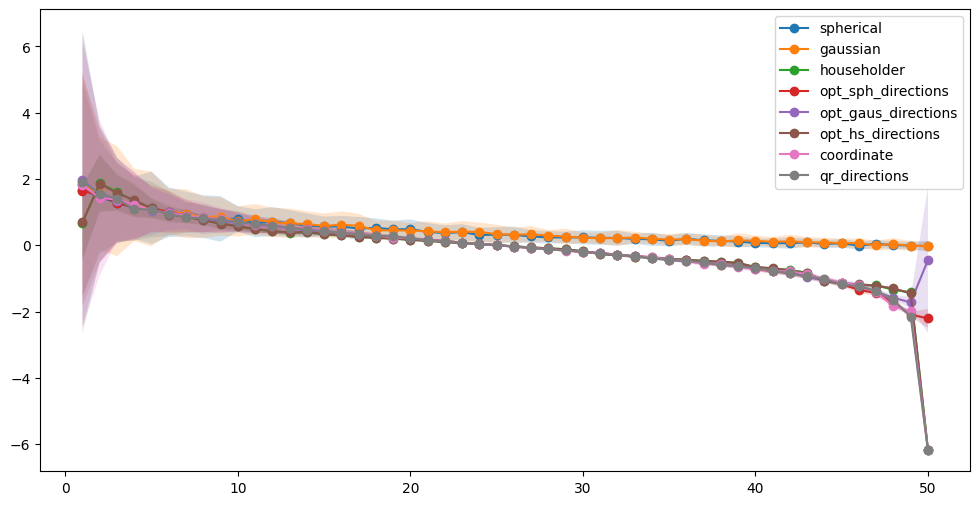

In [39]:
fig, ax = plt.subplots(figsize=(12, 6))

for label, values in results.items():
    mu = np.log(np.array([err[0] for err in values]))
    std = np.array([err[1] for err in values])
    ax.plot(num_directions, mu, 'o-', label=label)
    ax.fill_between(num_directions, mu - std, mu + std, alpha=0.2)

#ax.set_yscale('log')
ax.legend()